<>:86: SyntaxWarning: invalid escape sequence '\C'
<>:86: SyntaxWarning: invalid escape sequence '\C'
C:\Users\E114\AppData\Local\Temp\ipykernel_16072\3233490527.py:86: SyntaxWarning: invalid escape sequence '\C'
  mask_head = 'D:\Carla-0.10.0-Win64-Shipping\Carla-0.10.0-Win64-Shipping\datas\\training\Training_dataset_mask'



>>> 正在處理顏色: WHITE
  [white] Dist: 100cm | Score: 0.5368
  [white] Dist: 150cm | Score: 0.5562
  [white] Dist: 200cm | Score: 0.9304
  [white] Dist: 250cm | Score: 1.2920
  [white] Dist: 300cm | Score: 1.7382
  [white] Dist: 350cm | Score: 2.4193
  [white] Dist: 400cm | Score: 2.9223
  [white] Dist: 450cm | Score: 3.4483
  [white] Dist: 500cm | Score: 3.8221
  [white] Dist: 550cm | Score: 4.3316
  [white] Dist: 600cm | Score: 4.8059
  [white] Dist: 650cm | Score: 5.9974
  [white] Dist: 700cm | Score: 7.0711

>>> 正在處理顏色: BLACK
  [black] Dist: 100cm | Score: 0.4603
  [black] Dist: 150cm | Score: 0.7740
  [black] Dist: 200cm | Score: 1.0129
  [black] Dist: 250cm | Score: 1.4360
  [black] Dist: 300cm | Score: 1.9232
  [black] Dist: 350cm | Score: 2.8476
  [black] Dist: 400cm | Score: 3.7941
  [black] Dist: 450cm | Score: 4.5702
  [black] Dist: 500cm | Score: 5.2353
  [black] Dist: 550cm | Score: 6.1416
  [black] Dist: 600cm | Score: 6.6434
  [black] Dist: 650cm | Score: 8.0692
  [black] Di

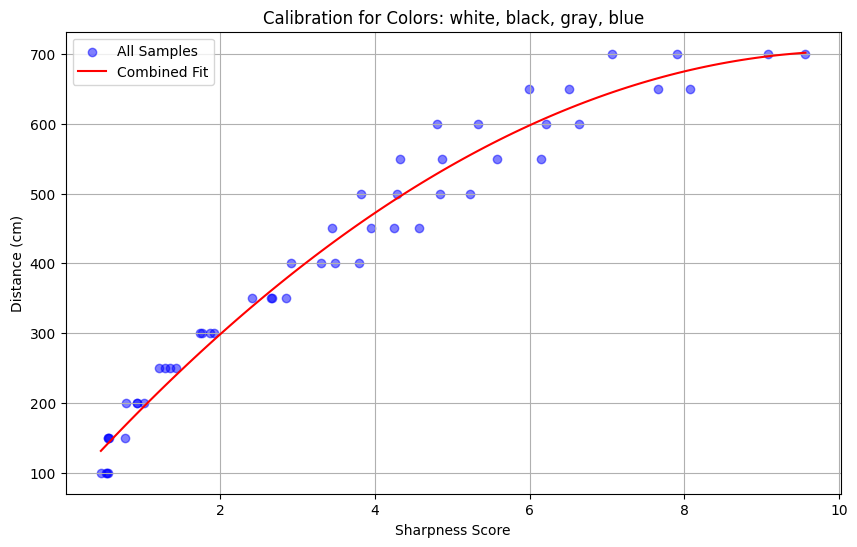


  ★ 擬合參數輸出 (Final Calibration Parameters) ★
  二次項 (a): -6.0419392310
  一次項 (b): 123.2324128784
  常數項 (c): 75.8282509016
  準確度 (R²): 0.9712
--------------------------------------------------
  公式: Distance = (-6.041939e+00)*x² + (1.232324e+02)*x + (75.828251)


In [ ]:
import numpy as np
import os
import cv2
import matplotlib.pyplot as plt
import glob
from scipy.optimize import curve_fit

# 確保 numpy 有 float_ 定義
if not hasattr(np, 'float_'):
    np.float_ = np.float64

try:
    import colour
except ImportError:
    print("錯誤: 找不到 'colour-science' 套件。")
    exit()

# ================= 參數設定 =================
# 使用萬用字元匹配所有 firetruck 系列資料夾
COLORS = ["white", 'black', 'gray', 'blue']  # 可以調參數，看要抓甚麼顏色

# 根據你的資料夾結構組合前綴
# 假設路徑是 ./datas/firetruck_red/Training_dataset...
DATA_BASE_PATH = "./datas/training/firetruck" # 自行調整資料夾參數

LARGER = "/R" 
BASE = 100   
PARA = 50    
MIN_VALID_DIST = 50 

W_J, W_AC, W_BC = 0.8136, 0.1782, 0.0081 # 目前學長跑最佳化出來的

# ================= 核心函式 (J, ac, bc) =================
def compute_sharpness_ciecam02_acbc(img, mask, w_j=0.6, w_ac=0.2, w_bc=0.2):
    if img is None: return None
    img_blur = cv2.GaussianBlur(img, (3, 3), 0)
    img_rgb = cv2.cvtColor(img_blur, cv2.COLOR_BGR2RGB)
    img_float = img_rgb.astype(np.float64) / 255.0

    XYZ = colour.sRGB_to_XYZ(img_float)
    XYZ_w = colour.xy_to_XYZ(colour.CCS_ILLUMINANTS['CIE 1931 2 Degree Standard Observer']['D65']) * 100
    L_A = 2000 / np.pi * 0.2
    Y_b = 20.0
    surround_cond = colour.VIEWING_CONDITIONS_CIECAM02['Average']
    
    try:
        specification = colour.XYZ_to_CIECAM02(
            XYZ * 100, XYZ_w, L_A, Y_b, surround=surround_cond
        )
        J = np.nan_to_num(specification.J)
        C = np.nan_to_num(specification.C)
        h = np.nan_to_num(specification.h)
        h_rad = np.deg2rad(h)
        ac = C * np.cos(h_rad)
        bc = C * np.sin(h_rad)
    except Exception:
        return None

    lap_J = cv2.Laplacian(J, cv2.CV_64F, ksize=3)
    lap_ac = cv2.Laplacian(ac, cv2.CV_64F, ksize=3)
    lap_bc = cv2.Laplacian(bc, cv2.CV_64F, ksize=3)

    weighted_gradient = w_j * (lap_J) + w_ac * (lap_ac) + w_bc * (lap_bc)
    
    if mask is not None:
        if mask.shape[::-1] != (img.shape[1], img.shape[0]): 
             mask = cv2.resize(mask, (img.shape[1], img.shape[0]), interpolation=cv2.INTER_NEAREST)
        mask_bool = (mask > 0)
        valid_pixels = weighted_gradient[mask_bool]
    else:
        valid_pixels = weighted_gradient.flatten()

    return np.std(valid_pixels) if len(valid_pixels) > 0 else None

# ================= 主程式 =================
def train_color_list_mode():
    all_dist_list = []
    all_score_list = []

    # --- 第一層迴圈：遍歷顏色陣列 ---
    for color in COLORS:
        # 動態組合資料夾路徑
        current_root = f"{DATA_BASE_PATH}_{color}"
        
        cal_head = os.path.join(current_root, "Test_dataset_Focus1500cm_f1.4_f22.0/")
        mask_head = 'D:\Carla-0.10.0-Win64-Shipping\Carla-0.10.0-Win64-Shipping\datas\\training\Training_dataset_mask'

        if not os.path.exists(cal_head):
            print(f"跳過：路徑不存在 {cal_head}")
            continue

        print(f"\n>>> 正在處理顏色: {color.upper()}")

        # 取得 T1, T2, T3... 資料夾
        all_subs = [d for d in os.listdir(cal_head) if os.path.isdir(os.path.join(cal_head, d))]
        t_folders = sorted([d for d in all_subs if d.startswith('T')], key=lambda x: int(x.replace('T', '')))

        # --- 第二層迴圈：遍歷各距離資料夾 ---
        for folder_name in t_folders:
            folder_num = int(folder_name.replace('T', ''))
            current_dist = BASE + (folder_num - 1) * PARA
            
            # 讀取 Mask (npy)
            mask_path = os.path.join(mask_head, f"T{folder_num}.npy")
            mask = np.load(mask_path) if os.path.exists(mask_path) else None

            # 讀取圖片路徑
            img_dir = os.path.join(cal_head, folder_name, LARGER.strip("/"))
            img_files = [f for f in glob.glob(os.path.join(img_dir, "*.*")) if f.lower().endswith(('.png', '.jpg', '.bmp'))]
            
            if not img_files: continue

            local_scores = []
            for f in img_files:
                img = cv2.imread(f)
                val = compute_sharpness_ciecam02_acbc(img, mask, w_j=W_J, w_ac=W_AC, w_bc=W_BC)
                if val is not None: local_scores.append(val)
            
            if local_scores:
                mean_val = np.mean(local_scores)
                all_score_list.append(mean_val)
                all_dist_list.append(current_dist)
                print(f"  [{color}] Dist: {current_dist}cm | Score: {mean_val:.4f}")

    # --- 數據擬合與繪圖 (與之前邏輯相同) ---
    X = np.array(all_score_list)
    Y = np.array(all_dist_list)
    
    # 過濾近距離干擾
    valid_mask = Y >= MIN_VALID_DIST
    X_train, Y_train = X[valid_mask], Y[valid_mask]

    if len(X_train) < 3:
        print("有效數據不足！")
        return

    # 多項式擬合
    coeffs = np.polyfit(X_train, Y_train, 2)
    poly_model = np.poly1d(coeffs)

    # 繪製結果
    plt.figure(figsize=(10, 6))
    plt.scatter(X, Y, c='blue', alpha=0.5, label='All Samples')
    x_range = np.linspace(X.min(), X.max(), 100)
    plt.plot(x_range, poly_model(x_range), 'r-', label='Combined Fit')
    plt.title(f"Calibration for Colors: {', '.join(COLORS)}")
    plt.xlabel("Sharpness Score")
    plt.ylabel("Distance (cm)")
    plt.legend()
    plt.grid(True)
    plt.show()
    # --- 數據擬合 ---
    X = np.array(all_score_list)
    Y = np.array(all_dist_list)

    # 1. 篩選數據 (排除小於 MIN_VALID_DIST 的點)
    valid_mask = Y >= MIN_VALID_DIST
    X_train, Y_train = X[valid_mask], Y[valid_mask]

    if len(X_train) < 3:
        print("\n[錯誤] 有效數據點不足，無法進行二次項擬合。")
        return

    # 2. 進行二次多項式擬合: Dist = a*Score^2 + b*Score + c
    coeffs = np.polyfit(X_train, Y_train, 2)
    a, b, c = coeffs  # 解構係數
    poly_model = np.poly1d(coeffs)

    # 3. 計算決定係數 R^2 (評估準確度)
    y_pred = poly_model(X_train)
    r_squared = 1 - (np.sum((Y_train - y_pred)**2) / np.sum((Y_train - np.mean(Y_train))**2))

    # ================= 輸出參數 =================
    print("\n" + "="*50)
    print("  ★ 擬合參數輸出 (Final Calibration Parameters) ★")
    print("="*50)
    print(f"  二次項 (a): {a:.10f}")
    print(f"  一次項 (b): {b:.10f}")
    print(f"  常數項 (c): {c:.10f}")
    print(f"  準確度 (R²): {r_squared:.4f}")
    print("-"*50)
    print(f"  公式: Distance = ({a:.6e})*x² + ({b:.6e})*x + ({c:.6f})")
    print("="*50)

if __name__ == "__main__":
    train_color_list_mode()

In [ ]:
""" Ciecam
Focal1500cm 0.7,0.3:  [1.2220e+05, 3.5671e-01, 8.4950e+01, -1.4407e+02]
Focal1000cm 0.7,0.3: [-1.1822e+07, -5.8183e+01, -9.2841e+03, -2.8223e+01]
J_ac_bc_0.6,0.2_0.2_sqrt&square: [-16.8844, 219.8914, -9.5102]
J_ac_bc_0.6,0.2_0.2: [-19.8946, 242.1283, -26.6663]
J_ac_bc_0.4,0.3_0.3: [-71.0792, 523.0101, -272.6011]
J_ac_bc_0.8,0.1_0.1: [-7.9723, 149.3583, 50.8018]
J_ac_bc_1.0,0,0: [-4.4995, 112.2126, 70.5595]
J_ac_bc white 0.8136, 0.1782, 0.0081: [-7.5323258673, 144.4508997851, 58.2860965893]
J_ac_bc white&black 0.8136, 0.1782, 0.0081: [-6.6823734229, 128.6131948063, 69.5838237713]
J_ac_bc white&black&gray 0.8136, 0.1782, 0.0081: [-6.5611905069, 128.8188047857, 68.4225055023]
J_ac_bc white&black&gray&blue 0.8136, 0.1782, 0.0081: [-6.041939e+00, 1.232324e+02, 75.828251]
"""

In [1]:
import numpy as np
import cv2
import os
import glob
import csv

# 確保 numpy 相容性
if not hasattr(np, 'float_'):
    np.float_ = np.float64

try:
    import colour
except ImportError:
    print("錯誤: 找不到 'colour-science' 套件。")
    print("請先執行: pip install colour-science")
    exit()

# ================= 固定參數設定 =================
GROUND_TRUTH = [1.2, 1.7, 2.2, 2.7, 3.2, 3.7, 4.2, 4.7, 5.2, 5.7, 6.2, 6.7]
W_J, W_AC, W_BC = 0.8136, 0.1782, 0.0081
PARAMS_POLY = [-6.041939e+00, 1.232324e+02, 75.828251]
OUTDIR = 'reverse_result/alternating_white&black&gray&blue/'

# 要輪流執行的顏色清單
# COLORS = ['red', 'green', 'blue', 'black', 'gray', 'deepGray', 'deep160Gray',  'deepRed', 'deepGreen', 'deepBlue','brown', 'chartreuse', 'cyan', 'magenta', 'orange', 'rose', 'springGreen', 'violet', 'yellow']
COLORS = ['red', 'green', 'blue', 'black']
# ================= 核心函式 =================

def poly2_model(x, coeffs):
    p = np.poly1d(coeffs)
    return p(x)

def compute_sharpness_ciecam02_acbc(img, mask, w_j=0.6, w_ac=0.2, w_bc=0.2):
    if img is None: return None
    img_blur = cv2.GaussianBlur(img, (3, 3), 0)
    img_float = cv2.cvtColor(img_blur, cv2.COLOR_BGR2RGB).astype(np.float64) / 255.0
    XYZ = colour.sRGB_to_XYZ(img_float)
    XYZ_w = colour.xy_to_XYZ(colour.CCS_ILLUMINANTS['CIE 1931 2 Degree Standard Observer']['D65']) * 100
    L_A, Y_b = 2000 / np.pi * 0.2, 20.0
    surround_cond = colour.VIEWING_CONDITIONS_CIECAM02['Average']
    
    try:
        spec = colour.XYZ_to_CIECAM02(XYZ * 100, XYZ_w, L_A, Y_b, surround=surround_cond)
        J, C, h = np.nan_to_num(spec.J), np.nan_to_num(spec.C), np.nan_to_num(spec.h)
        h_rad = np.deg2rad(h)
        ac, bc = C * np.cos(h_rad), C * np.sin(h_rad)
    except: return None

    lap_J = cv2.Laplacian(J, cv2.CV_64F, ksize=3)
    lap_ac = cv2.Laplacian(ac, cv2.CV_64F, ksize=3)
    lap_bc = cv2.Laplacian(bc, cv2.CV_64F, ksize=3)
    weighted_gradient = w_j * lap_J + w_ac * lap_ac + w_bc * lap_bc
    
    if mask is not None:
        if mask.shape[::-1] != (img.shape[1], img.shape[0]): 
            mask = cv2.resize(mask, (img.shape[1], img.shape[0]), interpolation=cv2.INTER_NEAREST)
        valid_pixels = weighted_gradient[mask > 0]
    else:
        valid_pixels = weighted_gradient.flatten()

    return np.std(valid_pixels) if len(valid_pixels) > 0 else None

# ================= 執行程序 =================

def run_color_process(color_name):
    # 動態定義路徑
    data_root_dir = rf'D:\Carla-0.10.0-Win64-Shipping\Carla-0.10.0-Win64-Shipping\datas\reverse\firetruck_{color_name}_reverse\Test_dataset_Focus1500cm_f1.4_f22.0'
    # mask_root_dir = rf'D:\Carla-0.10.0-Win64-Shipping\Carla-0.10.0-Win64-Shipping\datas\firetruck_{color_name}\Test_dataset_Focus1500cm_f1.4_f22.0_mask'
    mask_root_dir = rf'D:\Carla-0.10.0-Win64-Shipping\Carla-0.10.0-Win64-Shipping\datas\reverse\Test_dataset_Focus1500cm_f1.4_f22.0_mask_reverse'
    output_dir = OUTDIR
    output_csv = os.path.join(output_dir, f'test_results_{color_name}.csv')

    # 確保輸出目錄存在
    os.makedirs(output_dir, exist_ok=True)

    print(f"\n{'='*30} 開始處理顏色: {color_name.upper()} {'='*30}")
    print(f"資料目錄: {data_root_dir}")
    print(f"{'Folder':<8} | {'GT(m)':<8} | {'Sharpness':<12} | {'Pred(m)':<10} | {'Err(m)':<10} | {'Err %':<8}")
    print("-" * 100)

    mse_list = []
    csv_rows = []
    
    for i, gt_dist in enumerate(GROUND_TRUTH, 1):
        folder_name, mask_name = f"T{i:02d}", f"T{i}.npy"
        path_img_dir = os.path.join(data_root_dir, folder_name, 'R')
        path_mask = os.path.join(mask_root_dir, mask_name)

        if not os.path.exists(path_img_dir): 
            continue
        
        img_files = []
        for ext in ['*.jpg', '*.png', '*.bmp']:
            img_files.extend(glob.glob(os.path.join(path_img_dir, ext)))
        img_files.sort()

        mask = np.load(path_mask) if os.path.exists(path_mask) else None
        
        batch_scores = []
        for img_path in img_files:
            img = cv2.imread(img_path)
            score = compute_sharpness_ciecam02_acbc(img, mask, w_j=W_J, w_ac=W_AC, w_bc=W_BC)
            if score is not None: batch_scores.append(score)
        
        if batch_scores:
            avg_sharpness = np.mean(batch_scores)
            pred_m = poly2_model(avg_sharpness, PARAMS_POLY) / 100.0
            err = pred_m - gt_dist
            err_p = (abs(err) / gt_dist) * 100
            
            mse_list.append(err ** 2)
            
            # 即時列印輸出
            print(f"{folder_name:<8} | {gt_dist:<8.2f} | {avg_sharpness:<12.4f} | "
                  f"{pred_m:<10.2f} | {err:<10.2f} | {err_p:<7.2f}%")
            
            csv_rows.append([round(gt_dist, 2), round(pred_m, 2), round(err, 2), f"{round(err_p, 2)}%"])

    final_rmse = np.sqrt(np.mean(mse_list)) if mse_list else 0

    # 寫入 CSV
    with open(output_csv, mode='w', newline='', encoding='utf-8-sig') as f:
        writer = csv.writer(f)
        writer.writerow(['實際距離(m)', '推測距離(m)', '誤差(m)', '誤差百分比'])
        writer.writerows(csv_rows)
        writer.writerow([]) 
        writer.writerow(['總體 RMSE', f"{round(final_rmse, 4)} m", '', ''])

    print("-" * 100)
    print(f"顏色 {color_name} 完成！存檔至: {output_csv}")
    print(f"該色總 RMSE: {final_rmse:.4f} m\n")

# ================= 主程式迴圈 =================

if __name__ == "__main__":
    for color in COLORS:
        run_color_process(color)
    print("所有顏色測試完成！")


============================== 開始處理顏色: RED ==============================
資料目錄: D:\Carla-0.10.0-Win64-Shipping\Carla-0.10.0-Win64-Shipping\datas\reverse\firetruck_red_reverse\Test_dataset_Focus1500cm_f1.4_f22.0
Folder   | GT(m)    | Sharpness    | Pred(m)    | Err(m)     | Err %   
----------------------------------------------------------------------------------------------------
T01      | 1.20     | 0.5645       | 1.43       | 0.23       | 19.56  %
T02      | 1.70     | 0.6184       | 1.50       | -0.20      | 11.92  %
T03      | 2.20     | 1.1215       | 2.06       | -0.14      | 6.17   %
T04      | 2.70     | 1.5833       | 2.56       | -0.14      | 5.26   %
T05      | 3.20     | 2.0945       | 3.07       | -0.13      | 3.93   %
T06      | 3.70     | 2.8340       | 3.77       | 0.07       | 1.77   %
T07      | 4.20     | 3.4613       | 4.30       | 0.10       | 2.38   %
T08      | 4.70     | 3.8122       | 4.58       | -0.12      | 2.59   %
T09      | 5.20     | 4.3530       | 4.

In [2]:
import numpy as np
import cv2
import os
import glob
import csv
import matplotlib.pyplot as plt  # 用於繪圖

# 確保 numpy 相容性
if not hasattr(np, 'float_'):
    np.float_ = np.float64

try:
    import colour
except ImportError:
    print("錯誤: 找不到 'colour-science' 套件。")
    print("請先執行: pip install colour-science")
    exit()

# ================= 固定參數設定 =================
GROUND_TRUTH = [1.2, 1.7, 2.2, 2.7, 3.2, 3.7, 4.2, 4.7, 5.2, 5.7, 6.2, 6.7]
W_J, W_AC, W_BC = 0.8136, 0.1782, 0.0081
PARAMS_POLY = [-6.041939e+00, 1.232324e+02, 75.828251]
OUTDIR = 'result/alternating_white&black&gray&blue/'

# 要輪流執行的顏色清單
COLORS = ['red', 'green', 'blue', 'black', 'gray', 'deepGray', 'deep160Gray', 'deepRed', 'deepGreen', 'deepBlue', 'brown', 'chartreuse', 'cyan', 'magenta', 'orange', 'rose', 'springGreen', 'violet', 'yellow']

# 可用的圖標清單 (圓形, 下三角, 上三角, 左三角, 右三角, 正方形, 五角星, 八角星, 六角形, 鑽石)
MARKERS = ['o', 'v', '^', '<', '>', 's', 'p', '*', 'h', 'D']

# ================= 核心函式 =================

def poly2_model(x, coeffs):
    p = np.poly1d(coeffs)
    return p(x)

def compute_sharpness_ciecam02_acbc(img, mask, w_j=0.6, w_ac=0.2, w_bc=0.2):
    if img is None: return None
    img_blur = cv2.GaussianBlur(img, (3, 3), 0)
    img_float = cv2.cvtColor(img_blur, cv2.COLOR_BGR2RGB).astype(np.float64) / 255.0
    XYZ = colour.sRGB_to_XYZ(img_float)
    XYZ_w = colour.xy_to_XYZ(colour.CCS_ILLUMINANTS['CIE 1931 2 Degree Standard Observer']['D65']) * 100
    L_A, Y_b = 2000 / np.pi * 0.2, 20.0
    surround_cond = colour.VIEWING_CONDITIONS_CIECAM02['Average']
    
    try:
        spec = colour.XYZ_to_CIECAM02(XYZ * 100, XYZ_w, L_A, Y_b, surround=surround_cond)
        J, C, h = np.nan_to_num(spec.J), np.nan_to_num(spec.C), np.nan_to_num(spec.h)
        h_rad = np.deg2rad(h)
        ac, bc = C * np.cos(h_rad), C * np.sin(h_rad)
    except: return None

    lap_J = cv2.Laplacian(J, cv2.CV_64F, ksize=3)
    lap_ac = cv2.Laplacian(ac, cv2.CV_64F, ksize=3)
    lap_bc = cv2.Laplacian(bc, cv2.CV_64F, ksize=3)
    weighted_gradient = w_j * lap_J + w_ac * lap_ac + w_bc * lap_bc
    
    if mask is not None:
        if mask.shape[::-1] != (img.shape[1], img.shape[0]): 
            mask = cv2.resize(mask, (img.shape[1], img.shape[0]), interpolation=cv2.INTER_NEAREST)
        valid_pixels = weighted_gradient[mask > 0]
    else:
        valid_pixels = weighted_gradient.flatten()

    return np.std(valid_pixels) if len(valid_pixels) > 0 else None

# ================= 執行程序 =================

def run_color_process(color_name):
    data_root_dir = rf'D:\Carla-0.10.0-Win64-Shipping\Carla-0.10.0-Win64-Shipping\datas\firetruck_{color_name}\Test_dataset_Focus1500cm_f1.4_f22.0'
    mask_root_dir = rf'D:\Carla-0.10.0-Win64-Shipping\Carla-0.10.0-Win64-Shipping\datas\firetruck_{color_name}\Test_dataset_Focus1500cm_f1.4_f22.0_mask'
    output_dir = OUTDIR
    output_csv = os.path.join(output_dir, f'test_results_{color_name}.csv')

    os.makedirs(output_dir, exist_ok=True)

    print(f"\n{'='*30} 開始處理顏色: {color_name.upper()} {'='*30}")
    print(f"資料目錄: {data_root_dir}")
    print(f"{'Folder':<8} | {'GT(m)':<8} | {'Sharpness':<12} | {'Pred(m)':<10} | {'Err(m)':<10} | {'Err %':<8}")
    print("-" * 100)

    mse_list = []
    csv_rows = []
    
    # 用於記錄畫圖資料的清單 (X軸: 實際距離, Y軸: 誤差百分比)
    plot_gt = []
    plot_err_percent = []
    
    for i, gt_dist in enumerate(GROUND_TRUTH, 1):
        folder_name, mask_name = f"T{i:02d}", f"T{i}.npy"
        path_img_dir = os.path.join(data_root_dir, folder_name, 'R')
        path_mask = os.path.join(mask_root_dir, mask_name)

        if not os.path.exists(path_img_dir): 
            continue
        
        img_files = []
        for ext in ['*.jpg', '*.png', '*.bmp']:
            img_files.extend(glob.glob(os.path.join(path_img_dir, ext)))
        img_files.sort()

        mask = np.load(path_mask) if os.path.exists(path_mask) else None
        
        batch_scores = []
        for img_path in img_files:
            img = cv2.imread(img_path)
            score = compute_sharpness_ciecam02_acbc(img, mask, w_j=W_J, w_ac=W_AC, w_bc=W_BC)
            if score is not None: batch_scores.append(score)
        
        if batch_scores:
            avg_sharpness = np.mean(batch_scores)
            pred_m = poly2_model(avg_sharpness, PARAMS_POLY) / 100.0
            err = pred_m - gt_dist
            err_p = (abs(err) / gt_dist) * 100
            
            mse_list.append(err ** 2)
            
            # 儲存百分比資料用於畫圖
            plot_gt.append(gt_dist)
            plot_err_percent.append(err_p)
            
            print(f"{folder_name:<8} | {gt_dist:<8.2f} | {avg_sharpness:<12.4f} | "
                  f"{pred_m:<10.2f} | {err:<10.2f} | {err_p:<7.2f}%")
            
            csv_rows.append([round(gt_dist, 2), round(pred_m, 2), round(err, 2), f"{round(err_p, 2)}%"])

    final_rmse = np.sqrt(np.mean(mse_list)) if mse_list else 0

    with open(output_csv, mode='w', newline='', encoding='utf-8-sig') as f:
        writer = csv.writer(f)
        writer.writerow(['實際距離(m)', '推測距離(m)', '誤差(m)', '誤差百分比'])
        writer.writerows(csv_rows)
        writer.writerow([]) 
        writer.writerow(['總體 RMSE', f"{round(final_rmse, 4)} m", '', ''])

    print("-" * 100)
    print(f"顏色 {color_name} 完成！存檔至: {output_csv}")
    print(f"該色總 RMSE: {final_rmse:.4f} m\n")
    
    return (plot_gt, plot_err_percent) if plot_gt else None

# ================= 主程式迴圈 =================

if __name__ == "__main__":
    os.makedirs(OUTDIR, exist_ok=True)
    
    current_batch_data = []
    batch_count = 1

    for idx, color in enumerate(COLORS):
        result = run_color_process(color)
        
        if result is not None:
            current_batch_data.append((color, result[0], result[1]))
        
        # 每滿 5 個顏色，或到最後一個顏色時，輸出圖表
        if len(current_batch_data) == 5 or (idx == len(COLORS) - 1 and len(current_batch_data) > 0):
            plt.figure(figsize=(10, 6))
            
            for b_idx, (c_name, gt_list, err_p_list) in enumerate(current_batch_data):
                marker_style = MARKERS[b_idx % len(MARKERS)]
                
                plt.plot(gt_list, err_p_list, 
                         label=c_name, 
                         marker=marker_style, 
                         markersize=8, 
                         linewidth=1.5,
                         linestyle='-')
            
            # y=0 基準線（代表 0% 完美無誤差）
            plt.axhline(y=0, color='gray', linestyle='--', linewidth=1, alpha=0.7)
            
            # 設定圖表資訊 (縱軸改為 Error Percentage)
            plt.title(f'Distance Error Percentage Analysis (Batch {batch_count})', fontsize=14, fontweight='bold')
            plt.xlabel('Ground Truth Distance (m)', fontsize=12)
            plt.ylabel('Error Percentage (%)', fontsize=12)
            plt.grid(True, linestyle=':', alpha=0.6)
            plt.legend(loc='best')
            plt.tight_layout()
            
            # 儲存
            fig_path = os.path.join(OUTDIR, f'error_percent_batch_{batch_count}.png')
            plt.savefig(fig_path, dpi=300)
            plt.close()
            print(f" 成功輸出誤差百分比折線圖：{fig_path}\n")
            
            current_batch_data = []
            batch_count += 1
            
    print("所有顏色測試與百分比圖表繪製完成！")


============================== 開始處理顏色: RED ==============================
資料目錄: D:\Carla-0.10.0-Win64-Shipping\Carla-0.10.0-Win64-Shipping\datas\firetruck_red\Test_dataset_Focus1500cm_f1.4_f22.0
Folder   | GT(m)    | Sharpness    | Pred(m)    | Err(m)     | Err %   
----------------------------------------------------------------------------------------------------
T01      | 1.20     | 0.5653       | 1.44       | 0.24       | 19.63  %
T02      | 1.70     | 0.6184       | 1.50       | -0.20      | 11.92  %
T03      | 2.20     | 1.1215       | 2.06       | -0.14      | 6.17   %
T04      | 2.70     | 1.5833       | 2.56       | -0.14      | 5.26   %
T05      | 3.20     | 2.0945       | 3.07       | -0.13      | 3.93   %
T06      | 3.70     | 2.8340       | 3.77       | 0.07       | 1.77   %
T07      | 4.20     | 3.4613       | 4.30       | 0.10       | 2.38   %
T08      | 4.70     | 3.8122       | 4.58       | -0.12      | 2.59   %
T09      | 5.20     | 4.3530       | 4.98       | -0.22

In [5]:
import numpy as np
import os
import cv2
import glob
from scipy.optimize import minimize
import colour

# 確保 numpy 類型相容
if not hasattr(np, 'float_'):
    np.float_ = np.float64

# ================= 1. 特徵提取函式 =================
def extract_ciecam_features(img, mask):
    """提取 J, ac, bc 三個分量的 Laplacian 標準差"""
    if img is None: return None
    
    img_blur = cv2.GaussianBlur(img, (3, 3), 0)
    img_rgb = cv2.cvtColor(img_blur, cv2.COLOR_BGR2RGB)
    img_float = img_rgb.astype(np.float64) / 255.0

    # CIECAM02 轉換
    XYZ = colour.sRGB_to_XYZ(img_float)
    XYZ_w = colour.xy_to_XYZ(colour.CCS_ILLUMINANTS['CIE 1931 2 Degree Standard Observer']['D65']) * 100
    L_A, Y_b = 2000 / np.pi * 0.2, 20.0
    surround_cond = colour.VIEWING_CONDITIONS_CIECAM02['Average']
    
    try:
        spec = colour.XYZ_to_CIECAM02(XYZ * 100, XYZ_w, L_A, Y_b, surround=surround_cond)
        J, C, h = np.nan_to_num(spec.J), np.nan_to_num(spec.C), np.nan_to_num(spec.h)
        h_rad = np.deg2rad(h)
        ac, bc = C * np.cos(h_rad), C * np.sin(h_rad)
    except: return None

    # 分別計算三個通道的 Laplacian
    lap_J = cv2.Laplacian(J, cv2.CV_64F, ksize=3)
    lap_ac = cv2.Laplacian(ac, cv2.CV_64F, ksize=3)
    lap_bc = cv2.Laplacian(bc, cv2.CV_64F, ksize=3)

    if mask is not None:
        if mask.shape[::-1] != (img.shape[1], img.shape[0]):
            mask = cv2.resize(mask, (img.shape[1], img.shape[0]), interpolation=cv2.INTER_NEAREST)
        mask_bool = (mask > 0)
        return [np.std(lap_J[mask_bool]), np.std(lap_ac[mask_bool]), np.std(lap_bc[mask_bool])]
    else:
        return [np.std(lap_J), np.std(lap_ac), np.std(lap_bc)]

# ================= 2. 訓練資料預算階段 (包含檔名輸出) =================
def prepare_training_data(colors, base_path, mask_head):
    train_features = []  
    train_distances = [] 
    
    print("--- 開始特徵提取階段 (Preprocessing) ---")
    for color in colors:
        current_root = f"{base_path}_{color}"
        cal_head = os.path.join(current_root, "Test_dataset_Focus1500cm_f1.4_f22.0/")
        
        if not os.path.exists(cal_head):
            print(f"[跳過] 找不到顏色目錄: {current_root}")
            continue

        print(f"\n>>> 正在處理顏色資料夾: {color}")
        t_folders = sorted([d for d in os.listdir(cal_head) if d.startswith('T')], key=lambda x: int(x.replace('T', '')))

        for folder_name in t_folders:
            folder_num = int(folder_name.replace('T', ''))
            dist = 100 + (folder_num - 1) * 50 # 物理真實距離 (cm)
            
            mask_path = os.path.join(mask_head, f"T{folder_num}.npy")
            mask = np.load(mask_path) if os.path.exists(mask_path) else None

            img_dir = os.path.join(cal_head, folder_name, "R")
            img_files = glob.glob(os.path.join(img_dir, "*.*"))
            
            if not img_files:
                continue

            print(f"  [距離 {dist}cm] 目錄: {folder_name}")
            
            # 遍歷該資料夾內的所有圖片 (假設每個距離 10 張)
            folder_feats = []
            for img_path in img_files:
                # 輸出正在讀取的檔名
                print(f"    讀取圖片: {os.path.basename(img_path)}")
                
                img = cv2.imread(img_path)
                feat = extract_ciecam_features(img, mask)
                if feat:
                    folder_feats.append(feat)
            
            # 取該距離所有圖片特徵的平均值作為訓練點
            if folder_feats:
                avg_feat = np.mean(folder_feats, axis=0)
                train_features.append(avg_feat)
                train_distances.append(dist)
    
    return np.array(train_features), np.array(train_distances)

# ================= 3. 交替優化核心 =================
def alternating_optimization(X, y, max_iters=10):
    w = np.array([0.6, 0.2, 0.2])
    
    print("\n--- 開始交替優化 (Alternating Optimization) ---")
    for i in range(max_iters):
        # 階段 A: 固定權重，優化擬合曲線
        scores = np.dot(X, w)
        coeffs = np.polyfit(scores, y, 2)
        poly_model = np.poly1d(coeffs)
        
        # 階段 B: 固定曲線，優化權重
        def objective(weights):
            w_norm = weights / np.sum(weights)
            current_scores = np.dot(X, w_norm)
            predictions = poly_model(current_scores)
            return np.sqrt(np.mean((predictions - y)**2))

        res = minimize(objective, w, bounds=[(0.01, 1), (0.01, 1), (0.01, 1)])
        new_w = res.x / np.sum(res.x)

        if np.allclose(w, new_w, atol=1e-5):
            print(f"迭代 {i+1}: 已收斂。")
            break
        
        w = new_w
        print(f"迭代 {i+1}: 目前 RMSE = {res.fun:.4f} | 權重 J:{w[0]:.3f}, ac:{w[1]:.3f}, bc:{w[2]:.3f}")

    return w, coeffs

# ================= 4. 執行流程 =================
BASE_PATH = "./datas/training/firetruck"
MASK_PATH = r'D:\\Carla-0.10.0-Win64-Shipping\\Carla-0.10.0-Win64-Shipping\datas\\training\\Training_dataset_mask'
TRAIN_COLORS = ["white", "gray", "black"]

# 執行預算與優化
features, distances = prepare_training_data(TRAIN_COLORS, BASE_PATH, MASK_PATH)
best_w, best_coeffs = alternating_optimization(features, distances)

print("\n" + "="*50)
print("★ 優化流程結束 ★")
print(f"最終最佳權重 (Best Weights):")
print(f"  w_J  : {best_w[0]:.4f}")
print(f"  w_ac : {best_w[1]:.4f}")
print(f"  w_bc : {best_w[2]:.4f}")
print(f"擬合公式: Distance = {best_coeffs[0]:.4e}*x^2 + {best_coeffs[1]:.4e}*x + {best_coeffs[2]:.4f}")
print("="*50)

--- 開始特徵提取階段 (Preprocessing) ---

>>> 正在處理顏色資料夾: white
  [距離 100cm] 目錄: T01
    讀取圖片: D1.0_shot01.png
    讀取圖片: D1.0_shot02.png
    讀取圖片: D1.0_shot03.png
    讀取圖片: D1.0_shot04.png
    讀取圖片: D1.0_shot05.png
    讀取圖片: D1.0_shot06.png
    讀取圖片: D1.0_shot07.png
    讀取圖片: D1.0_shot08.png
    讀取圖片: D1.0_shot09.png
    讀取圖片: D1.0_shot10.png
  [距離 150cm] 目錄: T02
    讀取圖片: D1.5_shot01.png
    讀取圖片: D1.5_shot02.png
    讀取圖片: D1.5_shot03.png
    讀取圖片: D1.5_shot04.png
    讀取圖片: D1.5_shot05.png
    讀取圖片: D1.5_shot06.png
    讀取圖片: D1.5_shot07.png
    讀取圖片: D1.5_shot08.png
    讀取圖片: D1.5_shot09.png
    讀取圖片: D1.5_shot10.png
  [距離 200cm] 目錄: T03
    讀取圖片: D2.0_shot01.png
    讀取圖片: D2.0_shot02.png
    讀取圖片: D2.0_shot03.png
    讀取圖片: D2.0_shot04.png
    讀取圖片: D2.0_shot05.png
    讀取圖片: D2.0_shot06.png
    讀取圖片: D2.0_shot07.png
    讀取圖片: D2.0_shot08.png
    讀取圖片: D2.0_shot09.png
    讀取圖片: D2.0_shot10.png
  [距離 250cm] 目錄: T04
    讀取圖片: D2.5_shot01.png
    讀取圖片: D2.5_shot02.png
    讀取圖片: D2.5_shot03.png
   